<a href="https://colab.research.google.com/github/leman973/Deep-Learning/blob/main/VGG16_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,Dropout,GlobalAveragePooling2D

In [8]:
dataset = "/content/dataset/101_ObjectCategories"

print(os.listdir(dataset_path))

['airplanes', 'butterfly', 'sunflower', 'Motorbikes', 'elephant']


In [10]:
categories = ["airplanes","butterfly","elephant","Motorbikes","sunflower"]

In [11]:
images = []
labels = []

for index,category in enumerate(categories):
    folder = os.path.join(dataset,category)
    for image in os.listdir(folder):
        img_path = os.path.join(folder,image)
        img = load_img(img_path, target_size=(224,224))
        img = img_to_array(img)
        images.append(img)
        labels.append(index)

X = np.array(images)
Y = np.array(labels)

X = preprocess_input(X)

print("X_shape: ", X.shape)
print("Y_shape: ", Y.shape)

X_shape:  (1838, 224, 224, 3)
Y_shape:  (1838,)


In [12]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,Y,test_size = 0.2, random_state = 42, stratify = Y
)

print("Training images: ",X_train.shape)
print("Test images: ",Y_train.shape)

Training images:  (1470, 224, 224, 3)
Test images:  (1470,)


In [13]:
vgg16 = VGG16(weights = "imagenet", include_top = False, input_shape = (224,224,3))

for layer in vgg16.layers:
    layer.trainable = False

vgg16.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [14]:
model = Sequential([
    Input(shape=(224,224,3)),
    vgg16,
    GlobalAveragePooling2D(),
    Dense(128,activation="relu"),
    Dropout(0.3),
    Dense(64,activation="relu"),
    Dense(5,activation="softmax"),
])

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,788,933 (56.42 MB)

 Trainable params: 74,245 (290.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [16]:
model.compile(optimizer="adam", loss = "sparse_categorical_crossentropy", metrics=["accuracy"])

In [17]:
history = model.fit(X_train,Y_train, epochs = 15, batch_size=64, validation_split=0.2)

Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.7015 - loss: 2.7996 - val_accuracy: 0.9660 - val_loss: 0.1129
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 350ms/step - accuracy: 0.9719 - loss: 0.0751 - val_accuracy: 0.9898 - val_loss: 0.0567
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 352ms/step - accuracy: 0.9804 - loss: 0.0527 - val_accuracy: 0.9932 - val_loss: 0.0302
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 10s 354ms/step - accuracy: 0.9915 - loss: 0.0266 - val_accuracy: 0.9864 - val_loss: 0.0241
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 364ms/step - accuracy: 0.9940 - loss: 0.0216 - val_accuracy: 0.9898 - val_loss: 0.0352
Epoch 6/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 367ms/step - accuracy: 0.9957 - loss: 0.0126 - val_accuracy: 0.9932 - val_loss: 0.0345
Epoch 7/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 376ms/step - accuracy: 0.9949 - loss: 0.0164 - val_accuracy: 0.9932 - val_loss: 0.0244
Epoch 8/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 381ms/step - accuracy: 0.9957 - loss: 0.0138 - val_accuracy: 0.9

In [18]:
x_loss, x_accuracy = model.evaluate(X_test,Y_test)

12/12 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 1.0000 - loss: 0.0031


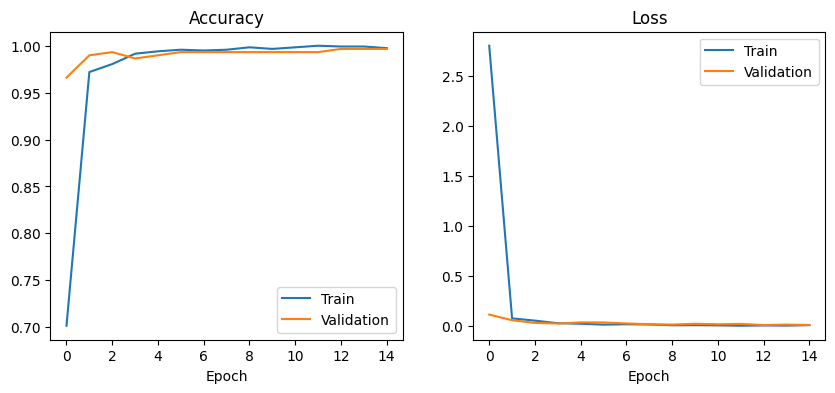

In [19]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

In [21]:
predictions = model.predict(X_test[:5])

predicted_classes = np.argmax(predictions, axis=1)

for i in range(5):
    print(
        "Actual:", categories[Y_test[i]],
        "| Predicted:", categories[predicted_classes[i]]
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
Actual: Motorbikes | Predicted: Motorbikes
Actual: Motorbikes | Predicted: Motorbikes
Actual: airplanes | Predicted: airplanes
Actual: butterfly | Predicted: butterfly
Actual: airplanes | Predicted: airplanes
